In [1]:
import json, os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.signal import butter, filtfilt, get_window, welch, spectrogram
import h5py

plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
os.makedirs("data", exist_ok=True)
os.makedirs("figs", exist_ok=True)

BASE = ("https://raw.githubusercontent.com/losc-tutorial/"
        "LOSC_Event_tutorial/master")
FILES = ["H-H1_LOSC_4_V2-1126259446-32.hdf5",
         "L-L1_LOSC_4_V2-1126259446-32.hdf5",
         "GW150914_4_template.hdf5",
         "BBH_events_v3.json"]

for f in FILES:
    p = os.path.join("data", f)
    if not os.path.exists(p):
        print("downloading", f)
        urllib.request.urlretrieve(f"{BASE}/{f}", p)
print("data ready")

Matplotlib is building the font cache; this may take a moment.


downloading H-H1_LOSC_4_V2-1126259446-32.hdf5
downloading L-L1_LOSC_4_V2-1126259446-32.hdf5
downloading GW150914_4_template.hdf5
downloading BBH_events_v3.json
data ready


In [2]:
meta = json.load(open("data/BBH_events_v3.json"))["GW150914"]
fs   = meta["fs"]           # 4096 Hz
dt   = 1.0 / fs
tev  = meta["tevent"]       # GPS time of the merger
flo, fhi = meta["fband"]    # 43-300 Hz analysis band

strain = {}
for det, key in [("H1", "fn_H1"), ("L1", "fn_L1")]:
    with h5py.File(f"data/{meta[key]}", "r") as fh:
        strain[det] = fh["strain/Strain"][()]
        gps0 = fh["meta/GPSstart"][()]

time = gps0 + np.arange(len(strain["H1"])) * dt

with h5py.File(f"data/{meta['fn_template']}", "r") as fh:
    tpl = fh["template"][()]
template = tpl[0].astype(np.float64)     # plus polarization

N = len(strain["H1"])
print(f"sample rate     : {fs} Hz")
print(f"samples         : {N}  ({N*dt:.0f} s)")
print(f"merger GPS time : {tev}")
print(f"analysis band   : {flo}-{fhi} Hz")
print(f"strain amplitude: {strain['H1'].std():.2e}  (dimensionless)")

sample rate     : 4096 Hz
samples         : 131072  (32 s)
merger GPS time : 1126259462.44
analysis band   : 43.0-300.0 Hz
strain amplitude: 2.20e-19  (dimensionless)


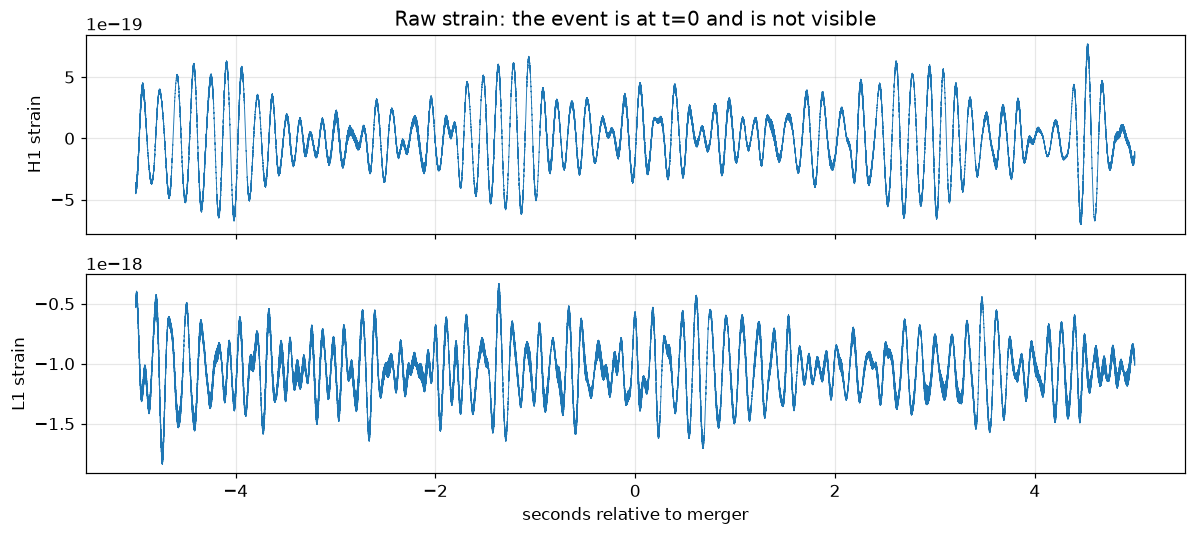

In [3]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(11, 5))
for a, det in zip(ax, ["H1", "L1"]):
    m = np.abs(time - tev) < 5
    a.plot(time[m] - tev, strain[det][m], lw=0.6)
    a.set_ylabel(f"{det} strain")
ax[1].set_xlabel("seconds relative to merger")
ax[0].set_title("Raw strain: the event is at t=0 and is not visible")
plt.tight_layout(); plt.savefig("figs/01_raw.png", dpi=150); plt.show()

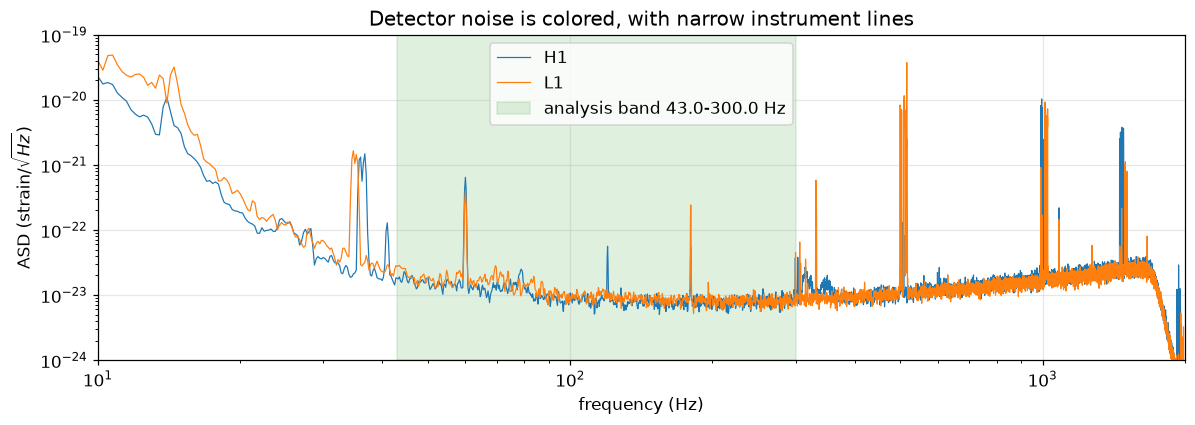

In [4]:
def psd_interp(x, fs, nfft=None):
    """Welch PSD estimate, returned as a callable PSD(f)."""
    nfft = nfft or 4 * fs
    f, Pxx = welch(x, fs=fs, nperseg=nfft, window="blackman")
    return f, Pxx, interp1d(f, Pxx, bounds_error=False, fill_value=np.inf)

psd = {}
plt.figure()
for det, c in [("H1", "C0"), ("L1", "C1")]:
    f, Pxx, psd[det] = psd_interp(strain[det], fs)
    plt.loglog(f, np.sqrt(Pxx), c, lw=0.8, label=det)
plt.axvspan(flo, fhi, color="C2", alpha=0.15, label=f"analysis band {flo}-{fhi} Hz")
plt.xlim(10, 2000); plt.ylim(1e-24, 1e-19)
plt.xlabel("frequency (Hz)"); plt.ylabel(r"ASD (strain/$\sqrt{Hz}$)")
plt.title("Detector noise is colored, with narrow instrument lines")
plt.legend(); plt.tight_layout(); plt.savefig("figs/02_asd.png", dpi=150); plt.show()

In [5]:
def whiten(x, psd_fn, dt):
    n = len(x)
    freqs = np.fft.rfftfreq(n, dt)
    hf = np.fft.rfft(x)
    norm = 1.0 / np.sqrt(1.0 / (dt * 2))
    return np.fft.irfft(hf / np.sqrt(psd_fn(freqs)) * norm, n=n)

# --- validation on synthetic noise of known amplitude ---
rng = np.random.default_rng(0)
test = rng.normal(0, 1e-19, N)
_, _, ptest = psd_interp(test, fs)
wtest = whiten(test, ptest, dt)
print(f"VALIDATION  synthetic white noise -> whitened std = {wtest.std():.4f}  (expect 1.0)")

VALIDATION  synthetic white noise -> whitened std = 0.9979  (expect 1.0)


In [6]:
white = {d: whiten(strain[d], psd[d], dt) for d in strain}

TRIM = 4                              # seconds discarded at each end
mid = slice(TRIM * fs, N - TRIM * fs)

for d in ["H1", "L1"]:
    print(f"{d}: whitened std  full record = {white[d].std():6.3f}   "
          f"edges trimmed = {white[d][mid].std():.3f}")
print("\nThe edge artifact, not the whitener, was the problem.")

H1: whitened std  full record =  6.273   edges trimmed = 0.995
L1: whitened std  full record =  4.179   edges trimmed = 1.006

The edge artifact, not the whitener, was the problem.


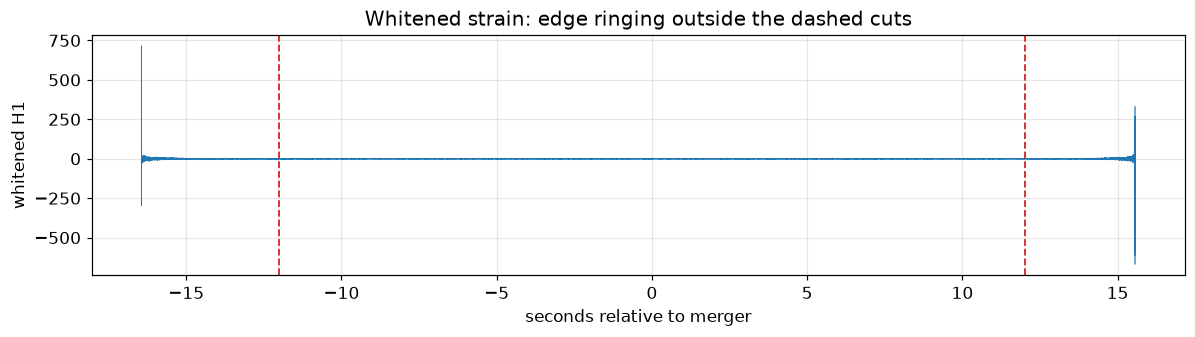

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(time - tev, white["H1"], lw=0.4)
for s in (-1, 1):
    ax.axvline(s * (N/2*dt - TRIM), color="C3", ls="--", lw=1.2)
ax.set_xlabel("seconds relative to merger"); ax.set_ylabel("whitened H1")
ax.set_title("Whitened strain: edge ringing outside the dashed cuts")
plt.tight_layout(); plt.savefig("figs/03_whiten_edges.png", dpi=150); plt.show()

In [8]:
def bandpass(x, fs, lo, hi, order=4):
    b, a = butter(order, [lo, hi], btype="bandpass", fs=fs)
    return filtfilt(b, a, x)

band = {d: bandpass(white[d], fs, flo, fhi) for d in white}

# consistency check: how much whitened power survives the band?
seg = white["H1"][mid]
F = np.fft.rfftfreq(len(seg), dt)
P = np.abs(np.fft.rfft(seg * np.hanning(len(seg))))**2
frac = P[(F >= flo) & (F < fhi)].sum() / P.sum()
print(f"fraction of whitened power inside {flo}-{fhi} Hz : {frac:6.3f}")
print(f"predicted bandpassed std = sqrt(frac)            : {np.sqrt(frac):6.3f}")
print(f"measured  bandpassed std                         : {band['H1'][mid].std():6.3f}")

fraction of whitened power inside 43.0-300.0 Hz :  0.127
predicted bandpassed std = sqrt(frac)            :  0.356
measured  bandpassed std                         :  0.335


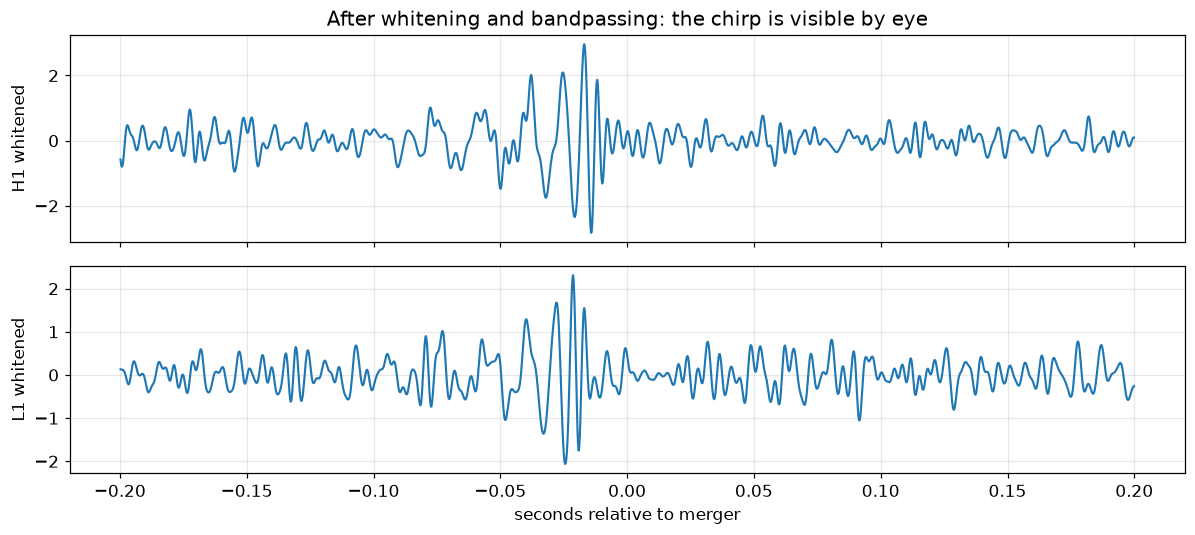

In [9]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(11, 5))
for a, d in zip(ax, ["H1", "L1"]):
    m = np.abs(time - tev) < 0.20
    a.plot(time[m] - tev, band[d][m], lw=1.4)
    a.set_ylabel(f"{d} whitened")
ax[1].set_xlabel("seconds relative to merger")
ax[0].set_title("After whitening and bandpassing: the chirp is visible by eye")
plt.tight_layout(); plt.savefig("figs/04_chirp.png", dpi=150); plt.show()

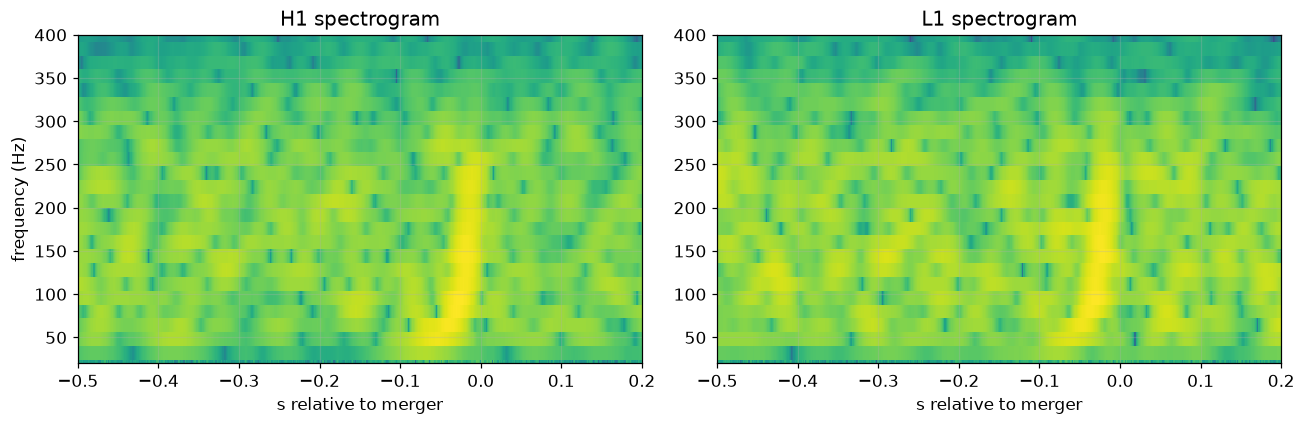

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, d in zip(ax, ["H1", "L1"]):
    m = np.abs(time - tev) < 4
    f_s, t_s, Sxx = spectrogram(band[d][m], fs=fs, nperseg=256,
                                noverlap=250, window="hann")
    a.pcolormesh(t_s - 4, f_s, np.log10(Sxx + 1e-12), shading="auto", cmap="viridis")
    a.set_ylim(20, 400); a.set_xlim(-0.5, 0.2)
    a.set_title(f"{d} spectrogram"); a.set_xlabel("s relative to merger")
ax[0].set_ylabel("frequency (Hz)")
plt.tight_layout(); plt.savefig("figs/05_spectrogram.png", dpi=150); plt.show()

In [11]:
def matched_filter(data, tmpl, psd_fn, fs):
    n = len(data); dt = 1.0 / fs; df = 1.0 / (n * dt)
    win = get_window(("tukey", 0.25), n)          # taper the record ends

    d_fft = np.fft.fft(data * win) * dt
    t_fft = np.fft.fft(tmpl * win) * dt
    power = psd_fn(np.abs(np.fft.fftfreq(n, dt)))

    optimal = d_fft * t_fft.conjugate() / power   # noise-weighted correlation
    opt_time = 2 * np.fft.ifft(optimal) / dt

    sigmasq = (t_fft * t_fft.conjugate() / power).sum() * df
    sigma = np.sqrt(np.abs(sigmasq))              # template norm

    return np.abs(np.roll(opt_time / sigma, n // 2))

snr = {d: matched_filter(strain[d], template, psd[d], fs) for d in strain}

peak = {}
for d in ["H1", "L1"]:
    i = int(np.argmax(snr[d][mid])) + TRIM * fs
    peak[d] = (snr[d][i], time[i])
    print(f"{d}: peak SNR = {snr[d][i]:5.2f}  at t = {time[i]:.4f}  "
          f"({time[i]-tev:+.4f} s from published merger time)")

H1: peak SNR = 24.25  at t = 1126259462.4404  (+0.0004 s from published merger time)
L1: peak SNR = 17.92  at t = 1126259462.4331  (-0.0069 s from published merger time)


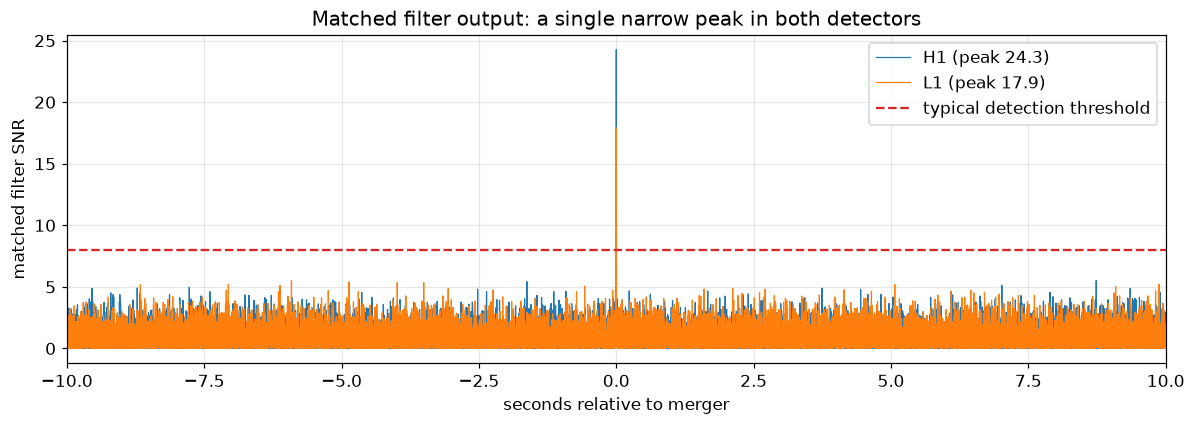

In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
for d, c in [("H1", "C0"), ("L1", "C1")]:
    ax.plot(time - tev, snr[d], c, lw=0.8, label=f"{d} (peak {peak[d][0]:.1f})")
ax.axhline(8, color="C3", ls="--", label="typical detection threshold")
ax.set_xlim(-10, 10); ax.set_xlabel("seconds relative to merger")
ax.set_ylabel("matched filter SNR"); ax.legend()
ax.set_title("Matched filter output: a single narrow peak in both detectors")
plt.tight_layout(); plt.savefig("figs/06_snr.png", dpi=150); plt.show()

In [13]:
# --- Check 1: coincidence between physically separated detectors ---
dt_hl = (peak["H1"][1] - peak["L1"][1]) * 1000
print("CHECK 1  independent detector coincidence")
print(f"  H1 minus L1 arrival time : {dt_hl:+.2f} ms")
print(f"  light travel time between sites : 10.0 ms")
print(f"  consistent: {abs(dt_hl) <= 10.0}")

CHECK 1  independent detector coincidence
  H1 minus L1 arrival time : +7.32 ms
  light travel time between sites : 10.0 ms
  consistent: True


CHECK 2  background distribution, event excluded
  background samples : 81920
  mean SNR           : 1.10
  loudest background : 5.67
  event peak         : 24.25
  event exceeds loudest noise by a factor of 4.3


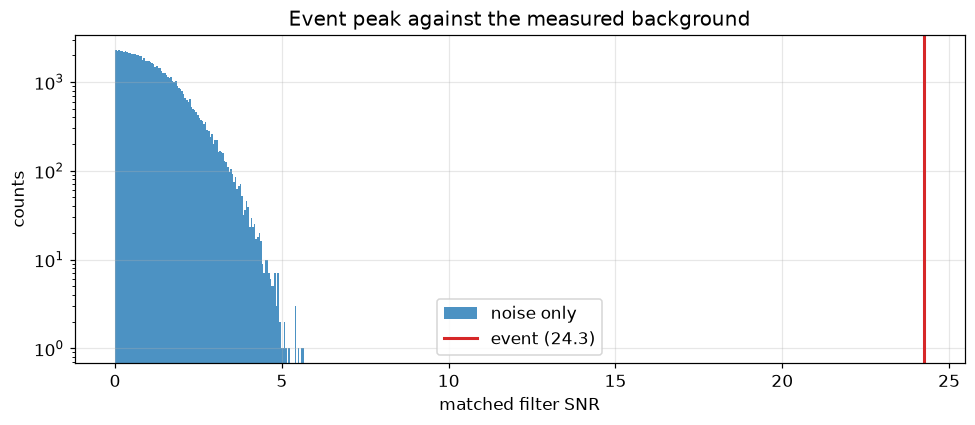

In [14]:
# --- Check 2: what SNR does noise alone produce? ---
bg = np.concatenate([snr["H1"][TRIM*fs : int((tev - time[0] - 2)*fs)],
                     snr["H1"][int((tev - time[0] + 2)*fs) : N - TRIM*fs]])

print("CHECK 2  background distribution, event excluded")
print(f"  background samples : {len(bg)}")
print(f"  mean SNR           : {bg.mean():.2f}")
print(f"  loudest background : {bg.max():.2f}")
print(f"  event peak         : {peak['H1'][0]:.2f}")
print(f"  event exceeds loudest noise by a factor of {peak['H1'][0]/bg.max():.1f}")

plt.figure(figsize=(9, 4))
plt.hist(bg, bins=120, log=True, alpha=0.8, label="noise only")
plt.axvline(peak["H1"][0], color="C3", lw=2, label=f"event ({peak['H1'][0]:.1f})")
plt.xlabel("matched filter SNR"); plt.ylabel("counts")
plt.title("Event peak against the measured background")
plt.legend(); plt.tight_layout(); plt.savefig("figs/07_background.png", dpi=150); plt.show()